# MobileNetV2 + attention + Grad-CAM++: plasma vs non-plasma cells (Google Colab)

**Data:** the already-segmented cells in `data/segmentation/` (`plasma cells/images` and `non-plasma cells/images`).

### Architecture
```
Input 224x224x3
  -> MobileNetV2 backbone, ImageNet weights, unchanged:
       17 x inverted-residual block
            [1x1 expand + BN + ReLU6] -> [3x3 depthwise + BN + ReLU6] -> [1x1 project + BN] (+ residual add)
  -> CBAM attention layer      <- the ONE addition you asked for (sits between the blocks and the pooling)
  -> Avg Pool
  -> FC (2 units)
  -> Softmax
```

| Step | What happens |
|---|---|
| 0 | GPU check, imports, seed |
| 1 | Mount Drive, point at `data/segmentation` |
| 2 | Copy the two `images` folders, check that they really are single cells |
| 3 | Build the table (image, label) |
| 4 | Split 75 / 10 / 15 |
| 5 | **Where the data actually comes from** (provenance of every split) |
| 6 | Class weights |
| 7 | Data pipeline + augmentation |
| 8 | Build MobileNetV2 + attention, verify the 17 blocks |
| 9 | Phase 1: train attention + FC |
| 10 | Phase 2: fine-tune the last blocks |
| 11 | Learning curves |
| 12 | Test evaluation |
| 13 | Look at mistakes |
| 14 | Grad-CAM++ |
| 15 | Save to Drive |

## Step 0: GPU, imports, seed
**Why:** training needs a GPU to be fast. Importing everything once keeps later cells short. A fixed seed makes the split and training repeatable.

In [1]:
import os, glob, shutil, random, time, json, re
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Mount Drive and point at the segmentation folder
**Why:** Colab can only read your files after Drive is mounted. The path goes to `data/segmentation`, the folder you told me to use. The `assert`s make a typo fail here instead of later.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

SEG = "/content/drive/MyDrive/PlasmaCells/PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/segmentation"
CLASS_FOLDERS = {                       # label 1 = plasma cell (positive), label 0 = non-plasma cell
    "non-plasma": f"{SEG}/non-plasma cells/images",
    "plasma":     f"{SEG}/plasma cells/images",
}
print("inside segmentation/:", os.listdir(SEG))
for name, p in CLASS_FOLDERS.items():
    assert os.path.isdir(p), f"not found: {p}"
    print(f"{name:11s} -> {p}")

Mounted at /content/drive
inside segmentation/: ['non-plasma cells', 'plasma cells']
non-plasma  -> /content/drive/MyDrive/PlasmaCells/PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/segmentation/non-plasma cells/images
plasma      -> /content/drive/MyDrive/PlasmaCells/PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/segmentation/plasma cells/images


## Step 2: Copy the two image folders and check they are single cells
**Why copy:** reading thousands of small files from Drive is slow; Colab's local disk is fast. We copy **only** these two folders.
**Why check:** you said these are the segmented cells. We print image sizes and show samples so you can confirm each picture is one cell and not a whole slide.

In [3]:
LOCAL = "/content/cells"
IMG_EXT = (".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff")
if not os.path.isdir(LOCAL):
    for name, p in CLASS_FOLDERS.items():
        shutil.copytree(p, f"{LOCAL}/{name}")

for name in CLASS_FOLDERS:
    files = sorted(f for f in os.listdir(f"{LOCAL}/{name}") if f.lower().endswith(IMG_EXT))
    sizes = [cv2.imread(f"{LOCAL}/{name}/{f}").shape[:2] for f in files[:200]]
    hs, ws = zip(*sizes)
    print(f"{name:11s} {len(files):5d} images | e.g. {files[:3]} | height {min(hs)}-{max(hs)} px, width {min(ws)}-{max(ws)} px (first 200)")

non-plasma   1932 images | e.g. ['1692243677854_p_1.jpg', '1692243677854_p_2.jpg', '1692243677862_p_3.jpg'] | height 111-310 px, width 113-301 px (first 200)
plasma       1616 images | e.g. ['1692243677854_p_0.jpg', '1692243677862_p_0.jpg', '1692243677862_p_1.jpg'] | height 149-421 px, width 121-367 px (first 200)


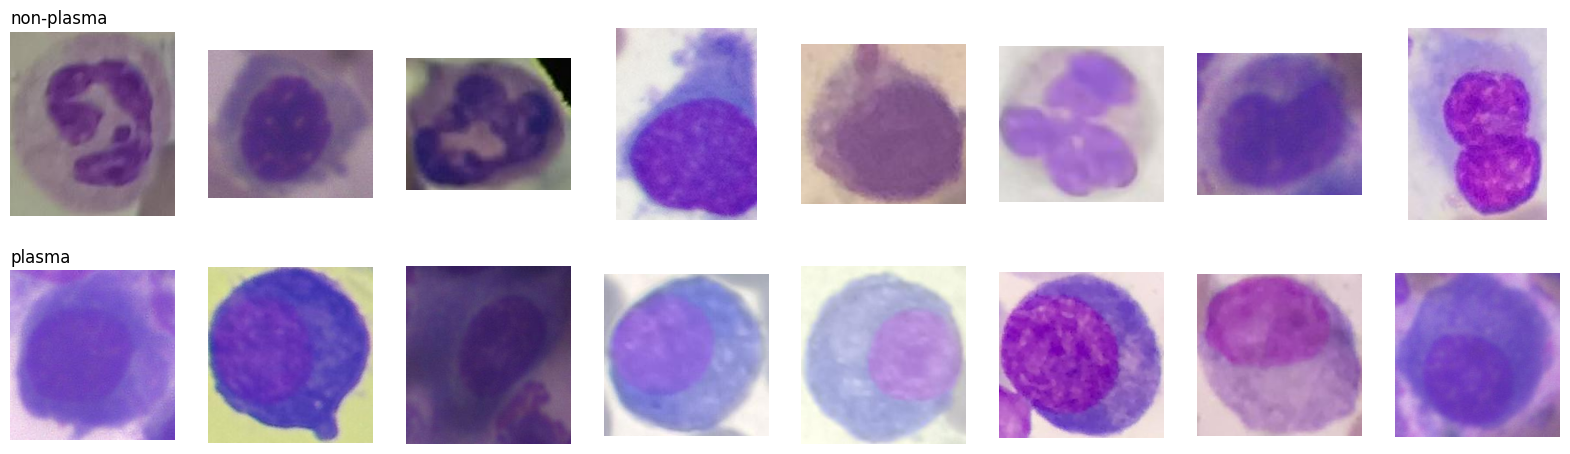

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for r, name in enumerate(CLASS_FOLDERS):
    files = sorted(f for f in os.listdir(f"{LOCAL}/{name}") if f.lower().endswith(IMG_EXT))
    for ax, f in zip(axes[r], random.Random(0).sample(files, 8)):
        ax.imshow(cv2.cvtColor(cv2.imread(f"{LOCAL}/{name}/{f}"), cv2.COLOR_BGR2RGB)); ax.axis("off")
    axes[r][0].set_title(name, loc="left")
plt.show()

## Step 3: Build the table of (image, label)
**Why:** everything downstream uses one table `df`. The label comes from the **folder** the image sits in: `plasma cells` = 1 (positive), `non-plasma cells` = 0. We also keep the original Drive path of each file, so Step 5 can show exactly where every image came from.

In [5]:
rows = []
for label, name in enumerate(CLASS_FOLDERS):          # non-plasma -> 0, plasma -> 1
    for f in sorted(os.listdir(f"{LOCAL}/{name}")):
        if f.lower().endswith(IMG_EXT):
            rows.append((f"{LOCAL}/{name}/{f}", f"{CLASS_FOLDERS[name]}/{f}", name, f, label))
df = pd.DataFrame(rows, columns=["path", "drive_path", "class_name", "file", "label"])
POS_NAME, NEG_NAME = "plasma", "non-plasma"
print(df.class_name.value_counts())
assert df.label.nunique() == 2

class_name
non-plasma    1932
plasma        1616
Name: count, dtype: int64


## Step 4: Split 75% train / 10% validation / 15% test
- **train (75%)**: the model learns from it. **validation (10%)**: we watch it to pick the best epoch and stop early. **test (15%)**: touched **once**, at the end.
- Two `train_test_split` calls: first 15% off for test, then 10% of the *total* (= 10/85 of what is left) off for validation. Both are **stratified**, so every split keeps the same plasma / non-plasma ratio.
- **Honest caveat:** this folder is one pool of cells with no patient or slide id, so we can't keep a patient's cells together. Cells from the same slide may land in different splits, which can make the test score a little optimistic. Say so in your report.

In [6]:
trval, test = train_test_split(df, test_size=0.15, stratify=df.label, random_state=SEED)
tr, val = train_test_split(trval, test_size=0.10 / 0.85, stratify=trval.label, random_state=SEED)
tr, val, test = (d.reset_index(drop=True) for d in (tr, val, test))
for n, d in [("train", tr), ("val", val), ("test", test)]:
    print(f"{n:5s} {len(d):5d} cells ({len(d)/len(df):5.1%}) | {POS_NAME}={int(d.label.sum())}  {NEG_NAME}={int((1-d.label).sum())}")

train  2660 cells (75.0%) | plasma=1211  non-plasma=1449
val     355 cells (10.0%) | plasma=162  non-plasma=193
test    533 cells (15.0%) | plasma=243  non-plasma=290


## Step 5: Where does the data actually come from?
You asked to see this right after the split. This step proves, for every split:
1. the **exact Drive folders** the images were read from and how many files each holds,
2. how many images of each class ended up in train / val / test,
3. that **no image appears in two splits** (otherwise the test score would be fake),
4. example **file paths** and a picture grid per split,
5. then it saves the split lists to Drive so the exact same split can be reproduced.

In [7]:
# 1. source folders
src = df.groupby("class_name").agg(files=("file", "count"), drive_folder=("drive_path", lambda s: os.path.dirname(s.iloc[0])))
display(src)

# 2. split x class
allsp = pd.concat([tr.assign(split="train"), val.assign(split="val"), test.assign(split="test")], ignore_index=True)
display(pd.crosstab(allsp.split, allsp.class_name, margins=True).loc[["train", "val", "test", "All"]])

# 3. no overlap, nothing lost
assert allsp.path.is_unique, "an image is in more than one split!"
assert len(allsp) == len(df), "some images were lost"
print("OK: every image is in exactly one split;", len(allsp), "images in total")

# 4. example paths
for sp in ["train", "val", "test"]:
    for cn in CLASS_FOLDERS:
        ex = allsp[(allsp.split == sp) & (allsp.class_name == cn)].drive_path.head(2).tolist()
        print(f"{sp:5s} {cn:11s}", [e.split('/data/')[-1] for e in ex])

,files,drive_folder
class_name,,
non-plasma,1932,/content/drive/MyDrive/PlasmaCells/PCMMD Plasm...
plasma,1616,/content/drive/MyDrive/PlasmaCells/PCMMD Plasm...


class_name,non-plasma,plasma,All
split,,,
train,1449,1211,2660
val,193,162,355
test,290,243,533
All,1932,1616,3548


OK: every image is in exactly one split; 3548 images in total
train non-plasma  ['segmentation/non-plasma cells/images/IMG01162_p_7.jpg', 'segmentation/non-plasma cells/images/1692243679199_p_1.jpg']
train plasma      ['segmentation/plasma cells/images/IMG_1931_p_1.jpg', 'segmentation/plasma cells/images/IMG00085_p_5.jpg']
val   non-plasma  ['segmentation/non-plasma cells/images/IMG_20230628_184934_p_11.jpg', 'segmentation/non-plasma cells/images/IMG_0050_p_4.jpg']
val   plasma      ['segmentation/plasma cells/images/1692243679801_p_0.jpg', 'segmentation/plasma cells/images/IMG_20230628_183303_p_2.jpg']
test  non-plasma  ['segmentation/non-plasma cells/images/IMG00085_p_10.jpg', 'segmentation/non-plasma cells/images/1692243678550_p_3.jpg']
test  plasma      ['segmentation/plasma cells/images/IMG_20230628_185730_p_0.jpg', 'segmentation/plasma cells/images/IMG_20230628_184923_p_1.jpg']


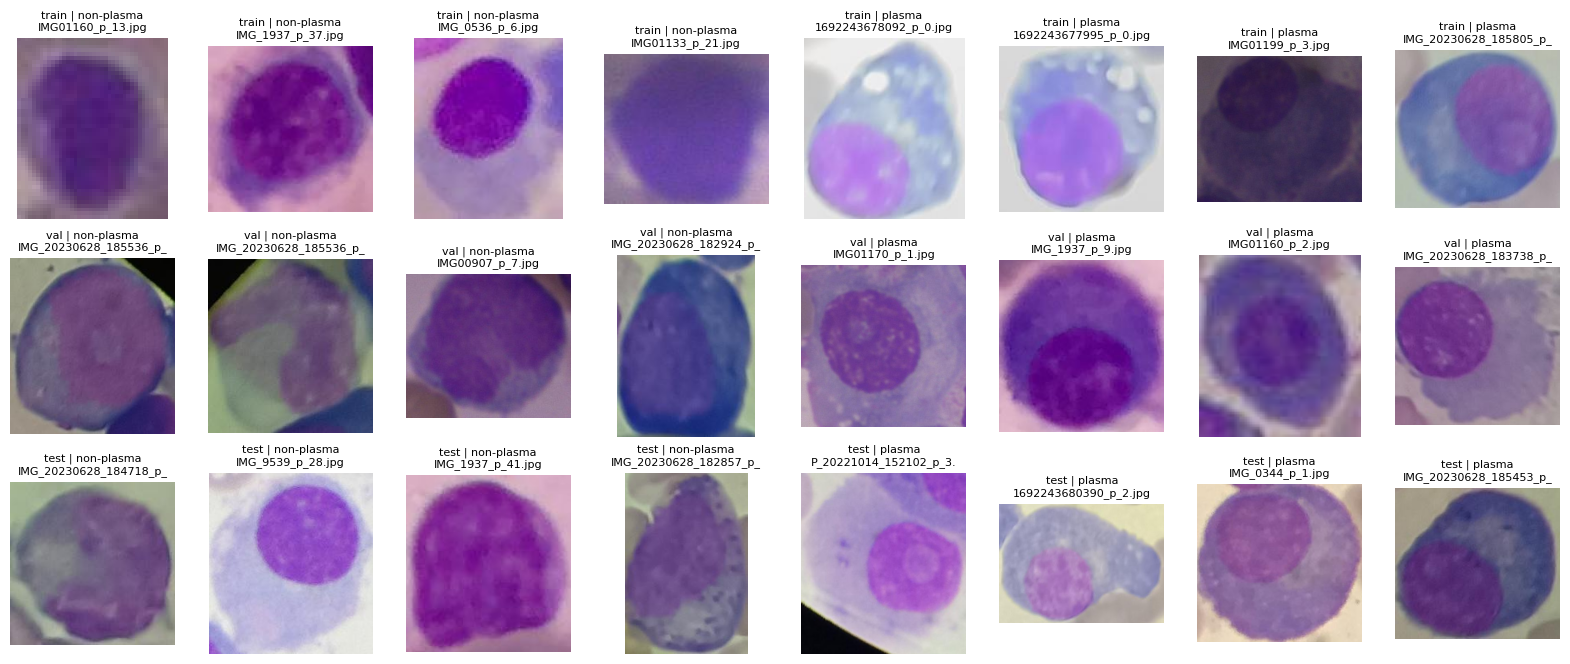

split list saved to /content/drive/MyDrive/MobileNetV2_results/split_assignment.csv


In [8]:
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
for r, sp in enumerate(["train", "val", "test"]):
    sub = allsp[allsp.split == sp]
    pick = pd.concat([sub[sub.label == 0].sample(4, random_state=1), sub[sub.label == 1].sample(4, random_state=1)])
    for ax, (_, x) in zip(axes[r], pick.iterrows()):
        ax.imshow(cv2.cvtColor(cv2.imread(x.path), cv2.COLOR_BGR2RGB)); ax.axis("off")
        ax.set_title(f"{sp} | {x.class_name}\n{x.file[:22]}", fontsize=8)
plt.show()

OUT = "/content/drive/MyDrive/MobileNetV2_results"; os.makedirs(OUT, exist_ok=True)
allsp[["split", "class_name", "label", "file", "drive_path"]].to_csv(f"{OUT}/split_assignment.csv", index=False)
print("split list saved to", f"{OUT}/split_assignment.csv")

## Step 6: Class weights
**Why:** if one class is more common, the model can score well by leaning towards it. Weights make mistakes on the rarer class cost more during training. Formula: `total / (2 x class count)`, computed from the **training set only** so nothing leaks from val/test.

In [9]:
n0, n1 = (tr.label == 0).sum(), (tr.label == 1).sum()
CLASS_WEIGHT = {0: len(tr) / (2 * n0), 1: len(tr) / (2 * n1)}
print(CLASS_WEIGHT)

{0: np.float64(0.9178743961352657), 1: np.float64(1.0982658959537572)}


## Step 7: Data pipeline and augmentation
- **Resize to 224x224**: the input size in your figure.
- **One-hot labels** (2 numbers per cell) because the output is a 2-unit **Softmax**.
- **Class weights are attached to each training sample** inside the pipeline (a third value per sample). This is explicit and works the same in every Keras version.
- **Augmentation** (flips, rotation, small zoom) runs inside the model and only while training. Cells have no 'up', so flips and rotations are safe. No colour changes, since stain colour may matter.
- **`preprocess_input`** is MobileNetV2's own scaling (pixels to [-1, 1]); it sits inside the model so train, val and test are treated identically.

In [10]:
SIZE, BATCH = 224, 32

def load_image(p):
    img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
    img = tf.image.resize(img, (SIZE, SIZE)); img.set_shape((SIZE, SIZE, 3))
    return img                                   # float32, still 0-255

def make_ds(frame, train):
    paths, labels = frame.path.values, frame.label.values
    if train:
        w = np.array([CLASS_WEIGHT[int(l)] for l in labels], dtype="float32")
        ds = tf.data.Dataset.from_tensor_slices((paths, labels, w)).shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda p, y, w: (load_image(p), tf.one_hot(y, 2), w), num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        ds = ds.map(lambda p, y: (load_image(p), tf.one_hot(y, 2)), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(tr, True), make_ds(val, False), make_ds(test, False)
augment = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"),
                            layers.RandomRotation(0.25), layers.RandomZoom(0.1)], name="augment")

## Step 8: Build MobileNetV2 + attention
**The backbone is the stock Keras MobileNetV2**, pre-trained on ImageNet and not modified. It is the architecture in your figure: 17 inverted-residual blocks, each `1x1 expand (BN+ReLU6) -> 3x3 depthwise (BN+ReLU6) -> 1x1 project (BN)` with the residual connection. (Keras also includes the standard stem conv before the blocks and a final 1x1 conv to 1280 channels after them; the figure leaves these out, but they are part of MobileNetV2.)

**The attention layer (your addition):** CBAM = *Convolutional Block Attention Module*. It learns two things about the final 7x7x1280 feature map:
- **channel attention**: which of the 1280 feature channels matter for telling plasma from non-plasma cells,
- **spatial attention**: which of the 7x7 locations (where in the cell) matter.

It multiplies the feature map by these learned importance weights. We place it **after the 17 blocks and before Avg Pool**, so the figure's pipeline stays intact: blocks -> (attention) -> Avg Pool -> FC -> Softmax.

**Head:** Avg Pool -> FC (2 units) -> Softmax. No dropout and no extra Dense layer, to follow the figure strictly.

In [11]:
class CBAM(layers.Layer):
    """Channel attention then spatial attention (Woo et al., 2018)."""
    def __init__(self, reduction=16, kernel_size=7, **kw):
        super().__init__(**kw)
        self.reduction, self.kernel_size = reduction, kernel_size
    def build(self, input_shape):
        ch = input_shape[-1]
        self.mlp1 = layers.Dense(ch // self.reduction, activation="relu")   # shared MLP for avg- and max-pooled descriptors
        self.mlp2 = layers.Dense(ch)
        self.spatial = layers.Conv2D(1, self.kernel_size, padding="same", activation="sigmoid")
        self.mlp1.build((None, ch)); self.mlp2.build((None, ch // self.reduction))   # create the weights now, not mid-training
        self.spatial.build((None, None, None, 2))
        super().build(input_shape)
    def call(self, x):
        avg = tf.reduce_mean(x, axis=[1, 2]); mx = tf.reduce_max(x, axis=[1, 2])
        ch_att = tf.sigmoid(self.mlp2(self.mlp1(avg)) + self.mlp2(self.mlp1(mx)))      # (batch, channels)
        x = x * ch_att[:, None, None, :]
        sp = tf.concat([tf.reduce_mean(x, axis=-1, keepdims=True), tf.reduce_max(x, axis=-1, keepdims=True)], axis=-1)
        return x * self.spatial(sp)                                                    # (batch, h, w, 1) map
    def compute_output_shape(self, input_shape):
        return input_shape

def build_mobilenetv2_attention():
    inp = keras.Input((SIZE, SIZE, 3))
    x = augment(inp)
    x = layers.Lambda(preprocess_input, name="mnv2_preprocess")(x)
    base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(SIZE, SIZE, 3))
    base.trainable = False
    x = base(x, training=False)                         # 7x7x1280 feature map after the 17 blocks
    x = CBAM(name="cbam_attention")(x)                  # attention (the one addition)
    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    logits = layers.Dense(2, name="fc_logits")(x)       # FC
    out = layers.Activation("softmax", name="softmax")(logits)
    return keras.Model(inp, out, name="MobileNetV2_CBAM"), base

model, base = build_mobilenetv2_attention()
n_blocks = len([l for l in base.layers if l.name.endswith("_project")])
print("inverted-residual blocks in the backbone:", n_blocks, "(your figure says 17)")
assert n_blocks == 17
print("residual (skip) connections:", len([l for l in base.layers if l.name.endswith("_add")]))
model.summary(line_length=90)

METRICS = [keras.metrics.CategoricalAccuracy(name="acc"), keras.metrics.AUC(name="auc", multi_label=True)]
def cbs():
    return [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)]

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
inverted-residual blocks in the backbone: 17 (your figure says 17)
residual (skip) connections: 10


Model: "MobileNetV2_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)              │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ augment (Sequential)                  │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ mnv2_preprocess (Lambda)              │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)     │ (None, 7, 7, 1280)           │       2,257,984 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ cbam_attention (CBAM)                 │ (None, 7, 7, 1280)           │         206,259 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ avg_pool (GlobalAveragePooling2D)     │ (None, 1280)                 │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ fc_logits (Dense)                     │ (None, 2)                    │           2,562 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ softmax (Activation)                  │ (None, 2)                    │               0 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 2,466,805 (9.41 MB)

 Trainable params: 208,821 (815.71 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Step 9: Phase 1, train only the new layers
**Why first:** the attention layer and the FC layer start random. If we trained the whole network now, their large random errors would flow back and damage MobileNetV2's good pre-trained weights. So the 17 backbone blocks are frozen; only attention + FC learn (learning rate 1e-3). **Early stopping** on validation AUC (patience 5) stops when validation stops improving and restores the best epoch.

In [12]:
t0 = time.time()
model.compile(keras.optimizers.Adam(1e-3), keras.losses.CategoricalCrossentropy(), metrics=METRICS)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=cbs(), verbose=2)

Epoch 1/15
84/84 - 22s - 257ms/step - acc: 0.8455 - auc: 0.9267 - loss: 0.3519 - val_acc: 0.8732 - val_auc: 0.9564 - val_loss: 0.3278 - learning_rate: 0.0010
Epoch 2/15
84/84 - 5s - 65ms/step - acc: 0.8992 - auc: 0.9632 - loss: 0.2433 - val_acc: 0.9042 - val_auc: 0.9628 - val_loss: 0.2488 - learning_rate: 0.0010
Epoch 3/15
84/84 - 6s - 70ms/step - acc: 0.9049 - auc: 0.9678 - loss: 0.2274 - val_acc: 0.8986 - val_auc: 0.9674 - val_loss: 0.2346 - learning_rate: 0.0010
Epoch 4/15
84/84 - 10s - 117ms/step - acc: 0.9139 - auc: 0.9711 - loss: 0.2135 - val_acc: 0.8732 - val_auc: 0.9648 - val_loss: 0.3321 - learning_rate: 0.0010
Epoch 5/15

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
84/84 - 6s - 67ms/step - acc: 0.9226 - auc: 0.9770 - loss: 0.1914 - val_acc: 0.8986 - val_auc: 0.9665 - val_loss: 0.2479 - learning_rate: 0.0010
Epoch 6/15
84/84 - 10s - 122ms/step - acc: 0.9226 - auc: 0.9782 - loss: 0.1877 - val_acc: 0.9099 - val_auc: 0.9752 - val_loss: 0.2136 - lea

## Step 10: Phase 2, fine-tune the last blocks
**Why:** the new layers are now sensible, so we let the last two blocks (`block_15`, `block_16`) and the final 1x1 conv (`Conv_1`), the most task-specific features, adapt to blood cells. **BatchNorm layers stay frozen** (standard practice: their statistics are fragile with small batches). Learning rate drops to 1e-5 so big steps don't erase what the network already knows. We must **recompile** after changing which layers are trainable, otherwise the change is ignored.

In [13]:
base.trainable = True
for l in base.layers:
    l.trainable = bool(re.match(r"(block_1[56]_|Conv_1$)", l.name)) and not isinstance(l, layers.BatchNormalization)
print("trainable backbone layers:", [l.name for l in base.layers if l.trainable])

model.compile(keras.optimizers.Adam(1e-5), keras.losses.CategoricalCrossentropy(), metrics=METRICS)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cbs(), verbose=2)
print(f"training time: {(time.time()-t0)/60:.1f} min")

trainable backbone layers: ['block_15_expand', 'block_15_expand_relu', 'block_15_depthwise', 'block_15_depthwise_relu', 'block_15_project', 'block_15_add', 'block_16_expand', 'block_16_expand_relu', 'block_16_depthwise', 'block_16_depthwise_relu', 'block_16_project', 'Conv_1']
Epoch 1/20
84/84 - 15s - 179ms/step - acc: 0.9396 - auc: 0.9847 - loss: 0.1495 - val_acc: 0.9183 - val_auc: 0.9803 - val_loss: 0.1930 - learning_rate: 1.0000e-05
Epoch 2/20
84/84 - 7s - 80ms/step - acc: 0.9432 - auc: 0.9885 - loss: 0.1368 - val_acc: 0.9352 - val_auc: 0.9823 - val_loss: 0.1689 - learning_rate: 1.0000e-05
Epoch 3/20
84/84 - 7s - 83ms/step - acc: 0.9455 - auc: 0.9859 - loss: 0.1477 - val_acc: 0.9408 - val_auc: 0.9821 - val_loss: 0.1692 - learning_rate: 1.0000e-05
Epoch 4/20

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
84/84 - 7s - 80ms/step - acc: 0.9447 - auc: 0.9883 - loss: 0.1367 - val_acc: 0.9408 - val_auc: 0.9830 - val_loss: 0.1752 - learning_rate: 1.0000e-05
Epo

## Step 11: Learning curves
**Why:** to see *how* it trained. Dashed line = start of fine-tuning. Training improving while validation stalls or worsens means overfitting.

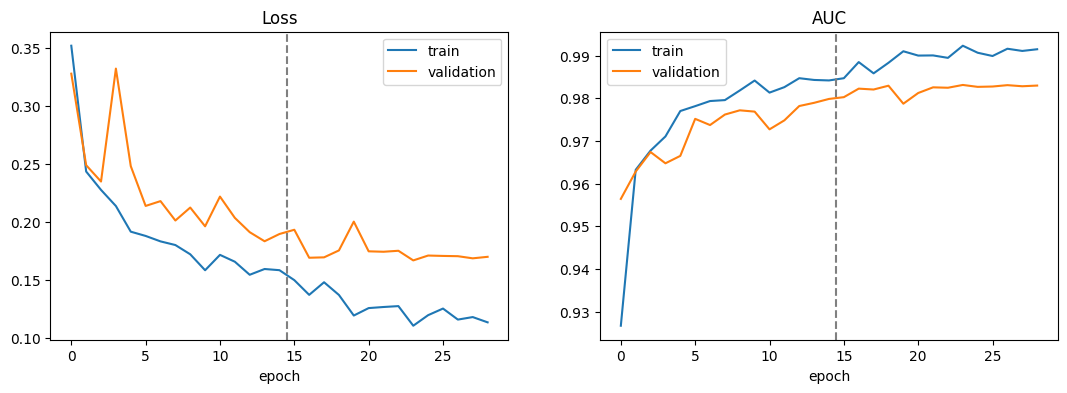

In [14]:
def cat(k): return h1.history[k] + h2.history[k]
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); k1 = len(h1.history["loss"])
for a, k, t in [(ax[0], "loss", "Loss"), (ax[1], "auc", "AUC")]:
    a.plot(cat(k), label="train"); a.plot(cat("val_" + k), label="validation")
    a.axvline(k1 - 0.5, ls="--", c="grey"); a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.savefig(f"{OUT}/curves.png", bbox_inches="tight"); plt.show()

## Step 12: Test evaluation, the one time we touch the test set
The Softmax gives two probabilities per cell; the predicted class is the larger one. **Metrics:** accuracy; *precision* (of cells called plasma, how many were); *recall* (of real plasma cells, how many we found); *F1*; *AUC* (ranking quality, independent of the cut-off). Plus the confusion matrix and ROC curve.

              precision    recall  f1-score   support

  non-plasma     0.9276    0.9276    0.9276       290
      plasma     0.9136    0.9136    0.9136       243

    accuracy                         0.9212       533
   macro avg     0.9206    0.9206    0.9206       533
weighted avg     0.9212    0.9212    0.9212       533

{'accuracy': 0.9212, 'precision': 0.9136, 'recall': 0.9136, 'f1': 0.9136, 'auc': 0.9812, 'n_train': 2660, 'n_val': 355, 'n_test': 533}


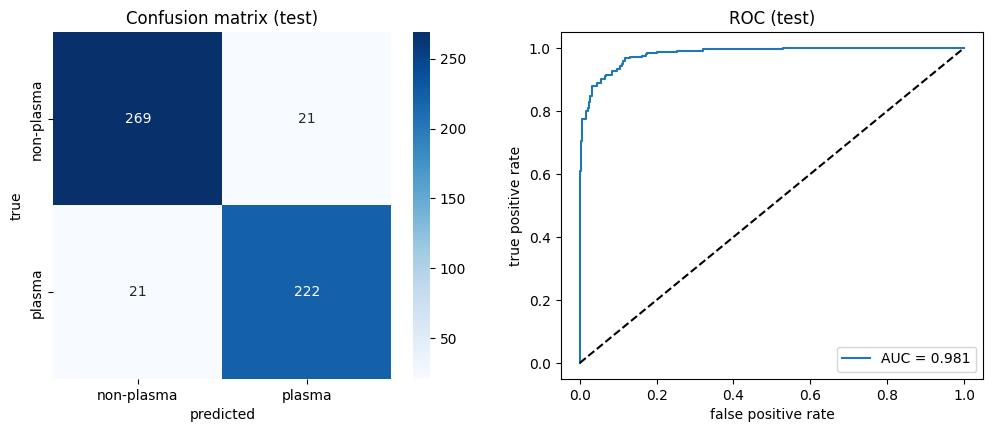

In [15]:
y_true = test.label.values
probs = model.predict(test_ds, verbose=0)              # shape (n, 2): [P(non-plasma), P(plasma)]
y_prob = probs[:, 1]; y_pred = probs.argmax(axis=1)
print(classification_report(y_true, y_pred, target_names=[NEG_NAME, POS_NAME], digits=4))

res = dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred),
           recall=recall_score(y_true, y_pred), f1=f1_score(y_true, y_pred), auc=float(roc_auc_score(y_true, y_prob)),
           n_train=len(tr), n_val=len(val), n_test=len(test))
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=[NEG_NAME, POS_NAME], yticklabels=[NEG_NAME, POS_NAME])
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_true, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {res['auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].set_title("ROC (test)"); ax[1].legend()
plt.savefig(f"{OUT}/test_eval.png", bbox_inches="tight"); plt.show()

## Step 13: Look at the mistakes
**Why:** numbers say *how often* it's wrong; pictures hint at *why* (blurry cell, odd stain, ambiguous shape).

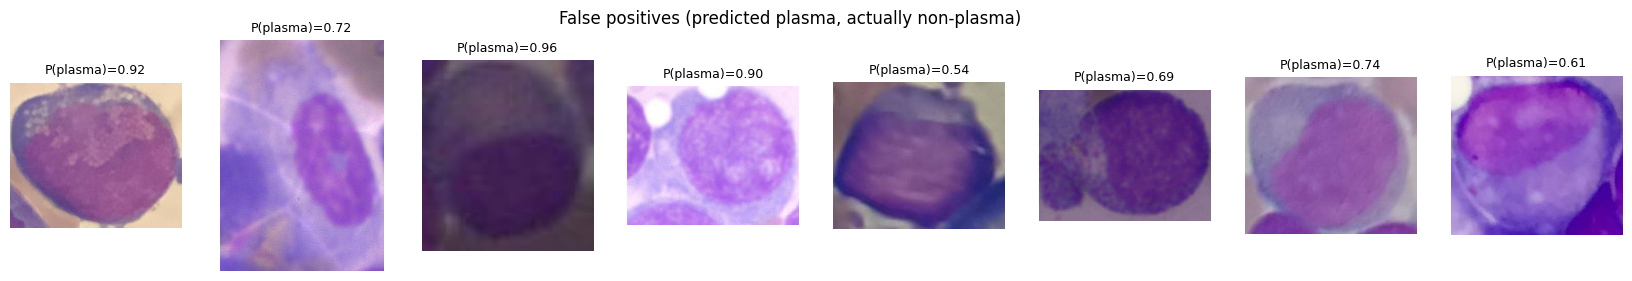

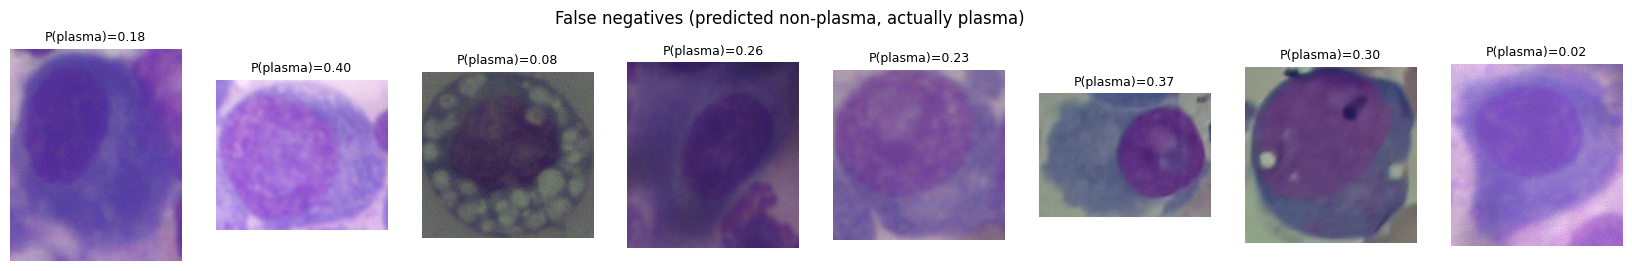

In [16]:
test["prob"], test["pred"] = y_prob, y_pred
for title, sub in [("False positives (predicted plasma, actually non-plasma)", test[(test.pred == 1) & (test.label == 0)]),
                   ("False negatives (predicted non-plasma, actually plasma)", test[(test.pred == 0) & (test.label == 1)])]:
    sub = sub.sample(min(8, len(sub)), random_state=0) if len(sub) else sub
    fig, axes = plt.subplots(1, max(len(sub), 1), figsize=(2.6 * max(len(sub), 1), 3), squeeze=False)
    for ax in axes[0]: ax.axis("off")
    for ax, (_, r) in zip(axes[0], sub.iterrows()):
        ax.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)); ax.set_title(f"P(plasma)={r.prob:.2f}", fontsize=9)
    fig.suptitle(title); plt.show()

## Step 14: Grad-CAM++
**What it shows:** a heat-map over the cell marking which regions pushed the model towards its decision. Red = strongly influenced the prediction. It lets you check the model is looking at the **cell** (nucleus, cytoplasm, halo) and not at the background or a stain artefact.

**How it works, in order:**
1. Take the feature map the model pools right after the attention layer (7x7x1280). This is the last place where "where" information still exists.
2. Run the cell through the network and take the **pre-softmax score** (logit) of the predicted class.
3. Compute the **gradient** of that score with respect to the feature map: how much each channel at each position matters.
4. **Grad-CAM++ weights** the gradients with higher-order terms (`alpha = g^2 / (2 g^2 + sum(A) g^3)`), which handles several small regions in one image better than plain Grad-CAM.
5. Weighted sum of the channels, keep the positive part (ReLU), normalise to 0-1, upscale to 224x224 and overlay on the cell.

We use the score *before* the softmax because Grad-CAM++'s formula assumes an un-squashed score.

In [17]:
# model that returns (feature map after attention, logits)
cam_model = keras.Model(model.input, [model.get_layer("cbam_attention").output, model.get_layer("fc_logits").output])

def gradcam_pp(img, class_idx=None):
    """img: float32 tensor (224,224,3), 0-255. Returns (cam 7x7 in [0,1], predicted class, P(plasma))."""
    x = tf.expand_dims(img, 0)
    with tf.GradientTape() as tape:
        A, logits = cam_model(x, training=False)               # A: (1, 7, 7, 1280)
        if class_idx is None:
            class_idx = int(tf.argmax(logits[0]))
        score = logits[:, class_idx]
    g = tape.gradient(score, A)                                # d score / d A
    g2, g3 = g ** 2, g ** 3
    denom = 2.0 * g2 + tf.reduce_sum(A, axis=(1, 2), keepdims=True) * g3
    alpha = tf.where(denom != 0.0, g2 / tf.where(denom != 0.0, denom, tf.ones_like(denom)), tf.zeros_like(g))
    w = tf.reduce_sum(alpha * tf.nn.relu(g), axis=(1, 2))      # (1, 1280) channel weights
    cam = tf.nn.relu(tf.reduce_sum(w[:, None, None, :] * A, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    p_plasma = float(tf.nn.softmax(logits[0])[1])
    return cam, class_idx, p_plasma

def overlay(rgb_uint8, cam, alpha=0.45):
    heat = cv2.applyColorMap(np.uint8(255 * cv2.resize(cam, (SIZE, SIZE))), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return np.uint8((1 - alpha) * rgb_uint8 + alpha * heat)

def show_cams(frame, title, n=6):
    frame = frame.sample(min(n, len(frame)), random_state=0) if len(frame) else frame
    if len(frame) == 0: print("none:", title); return
    fig, axes = plt.subplots(2, len(frame), figsize=(2.8 * len(frame), 6), squeeze=False)
    for j, (_, r) in enumerate(frame.iterrows()):
        img = load_image(r.path)
        cam, c, p = gradcam_pp(img)
        rgb = img.numpy().astype("uint8")
        axes[0][j].imshow(rgb); axes[0][j].axis("off")
        axes[0][j].set_title(f"true: {[NEG_NAME, POS_NAME][r.label]}", fontsize=9)
        axes[1][j].imshow(overlay(rgb, cam)); axes[1][j].axis("off")
        axes[1][j].set_title(f"pred: {[NEG_NAME, POS_NAME][c]} (P plasma={p:.2f})", fontsize=8)
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT}/gradcampp_{title.split(':')[0].replace(' ', '_')}.png", bbox_inches="tight"); plt.show()

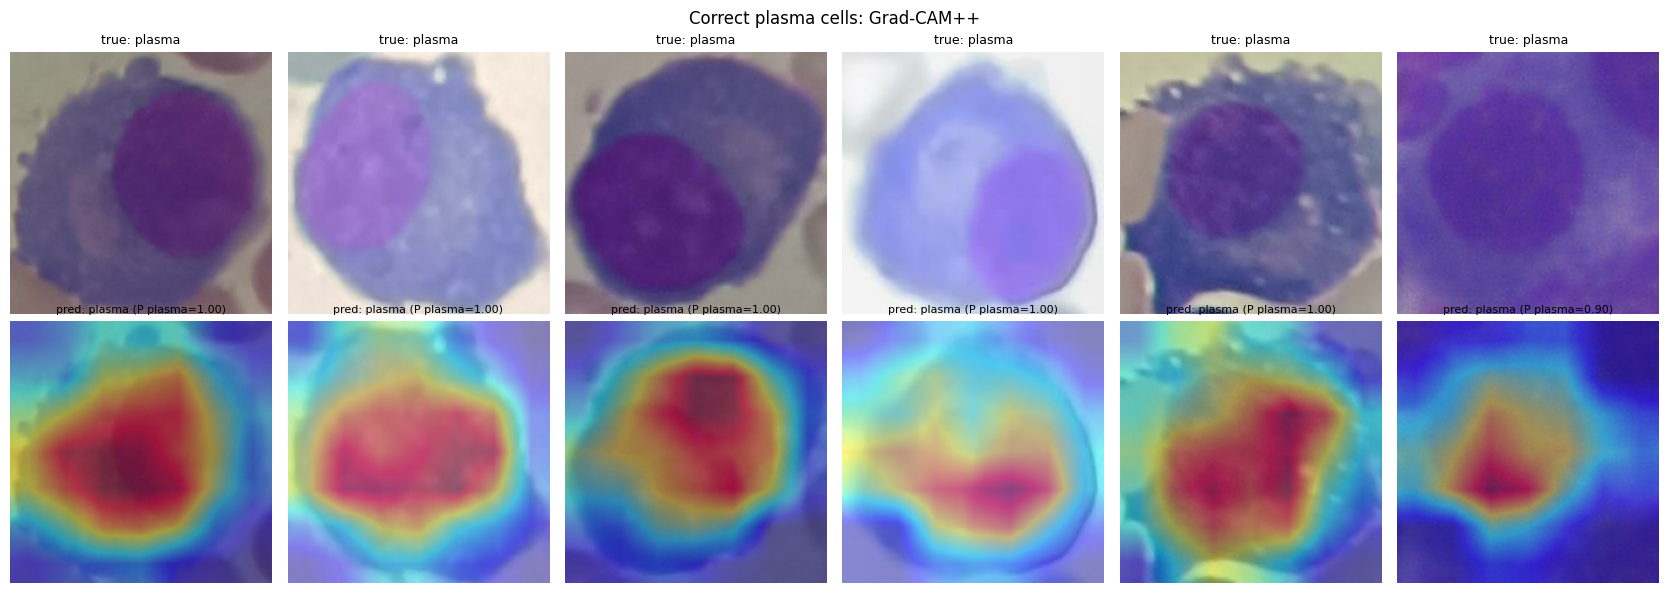

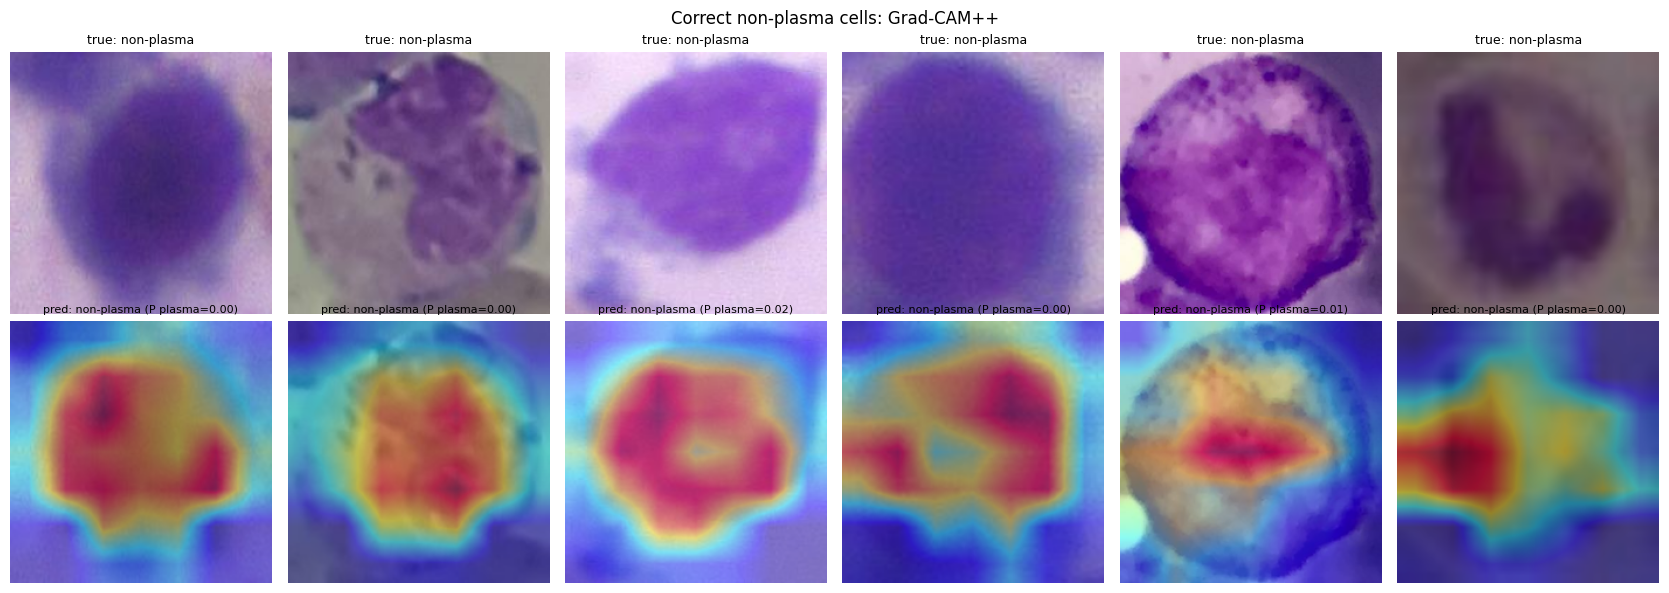

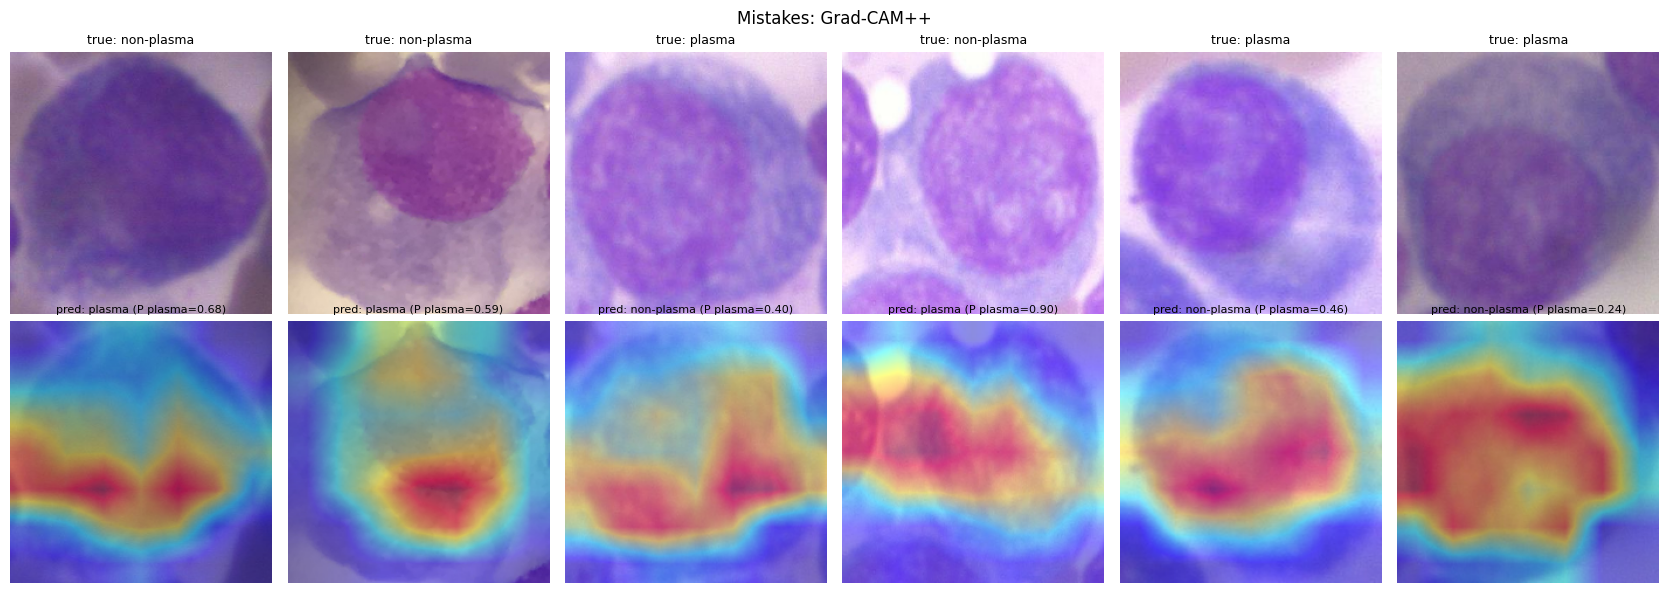

In [18]:
show_cams(test[(test.label == 1) & (test.pred == 1)], "Correct plasma cells: Grad-CAM++")
show_cams(test[(test.label == 0) & (test.pred == 0)], "Correct non-plasma cells: Grad-CAM++")
show_cams(test[test.label != test.pred], "Mistakes: Grad-CAM++")

**How to read them:** if the red regions sit on the cell (especially nucleus and cytoplasm), the model is using sensible evidence. If they sit on background or the image corner, the model may be exploiting an artefact; treat the score with suspicion. Compare the *correct* rows with the *mistakes* row: mistakes often show attention drifting off the cell or onto an ambiguous region.

## Step 15: Save everything to Drive
**Why:** Colab's disk is wiped when the session ends. We keep the weights (rebuild with `build_mobilenetv2_attention()` then `model.load_weights(...)`), the metrics and the test predictions. The split list was already saved in Step 5.

In [19]:
model.save_weights(f"{OUT}/mobilenetv2_cbam.weights.h5")
json.dump(res, open(f"{OUT}/test_metrics.json", "w"), indent=2)
test[["file", "drive_path", "label", "prob", "pred"]].to_csv(f"{OUT}/test_predictions.csv", index=False)
print("saved to", OUT)

saved to /content/drive/MyDrive/MobileNetV2_results


## For the write-up
- Data: `data/segmentation/` of the PCMMD dataset, plasma cells vs non-plasma cells (the labels are plasma vs non-plasma, not malignant vs normal), with the number of cells per class and per split.
- Split: 75/10/15 random and stratified; a **cell pool without patient ids**, so cells from the same patient/slide may sit in different splits; the test score may be optimistic.
- Architecture: MobileNetV2 (17 inverted-residual blocks, ImageNet weights) + CBAM attention + Avg Pool + FC(2) + Softmax. Say that the attention layer is the only addition to the standard architecture.
- Training: two phases (head only, then last two blocks), class-weighted cross-entropy, early stopping on validation AUC.
- One run is one sample; for a stronger claim, repeat with 3 seeds and report mean ± std.
- Grad-CAM++ is a visual explanation, not proof the model reasons like a haematologist.